<a href="https://colab.research.google.com/github/JamesTang616/skeleton_extract/blob/main/Vedio_%5BMediaPipe_Python_Tasks%5D_Pose_Landmarker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##### Copyright 2023 The MediaPipe Authors. All Rights Reserved.

In [1]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Pose Landmarks Detection with MediaPipe Tasks

This notebook shows you how to use MediaPipe Tasks Python API to detect pose landmarks from images.

## Preparation

Let's start with installing MediaPipe.


In [2]:
!pip install -q mediapipe huggingface_hub

Then download an off-the-shelf model bundle. Check out the [MediaPipe documentation](https://developers.google.com/mediapipe/solutions/vision/pose_landmarker#models) for more information about this model bundle.

In [3]:
from huggingface_hub import hf_hub_download

model_path = hf_hub_download(
    repo_id='litert-community/MediaPipe-PoseLandmarker-Heavy',
    filename='pose_landmarker_heavy.task',
)

pose_landmarker_heavy.task: reconstructing file:   0%|          |  0.00B / 30.7MB            

pose_landmarker_heavy.task: downloading bytes:           |  0.00B            

## Visualization utilities

In [4]:
import numpy as np
from mediapipe.tasks.python.vision import drawing_utils
from mediapipe.tasks.python.vision import drawing_styles
from mediapipe.tasks.python import vision


def draw_landmarks_on_image(rgb_image, detection_result):
  pose_landmarks_list = detection_result.pose_landmarks
  # On macOS, mp.Image.create_from_file() returns RGBA data. The drawing
  # utilities need three channels, so drop the alpha channel if there is one.
  annotated_image = np.copy(rgb_image[:, :, :3])

  pose_landmark_style = drawing_styles.get_default_pose_landmarks_style()
  pose_connection_style = drawing_utils.DrawingSpec(color=(0, 255, 0), thickness=2)

  for pose_landmarks in pose_landmarks_list:
    drawing_utils.draw_landmarks(
        image=annotated_image,
        landmark_list=pose_landmarks,
        connections=vision.PoseLandmarksConnections.POSE_LANDMARKS,
        landmark_drawing_spec=pose_landmark_style,
        connection_drawing_spec=pose_connection_style)

  return annotated_image

## Download test image

To demonstrate the Pose Landmarker API, you can download a sample image using the follow code. The image is from [Pixabay](https://pixabay.com/photos/girl-woman-fitness-beautiful-smile-4051811/).

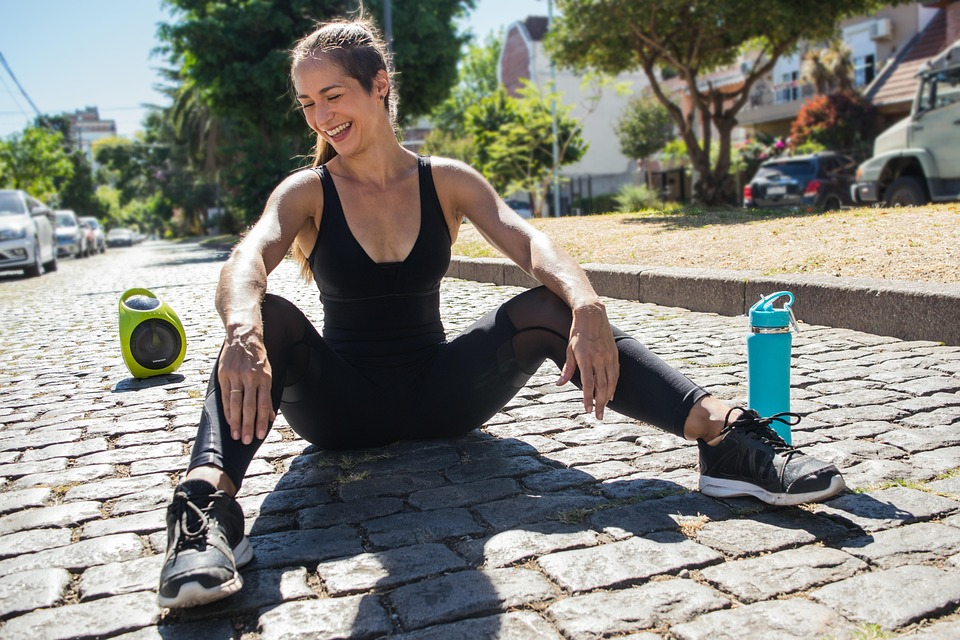

In [5]:
!wget -q -O image.jpg https://cdn.pixabay.com/photo/2019/03/12/20/39/girl-4051811_960_720.jpg

import cv2
from google.colab.patches import cv2_imshow

img = cv2.imread("image.jpg")
cv2_imshow(img)

Optionally, you can upload your own image. If you want to do so, uncomment and run the cell below.

In [6]:
# from google.colab import files
# uploaded = files.upload()

# for filename in uploaded:
#   content = uploaded[filename]
#   with open(filename, 'wb') as f:
#     f.write(content)

# if len(uploaded.keys()):
#   IMAGE_FILE = next(iter(uploaded))
#   print('Uploaded file:', IMAGE_FILE)

## Running inference and visualizing the results

The final step is to run pose landmark detection on your selected image. This involves creating your PoseLandmarker object, loading your image, running detection, and finally, the optional step of displaying the image with visualizations.

Check out the [MediaPipe documentation](https://developers.google.com/mediapipe/solutions/vision/pose_landmarker/python) to learn more about configuration options that this solution supports.


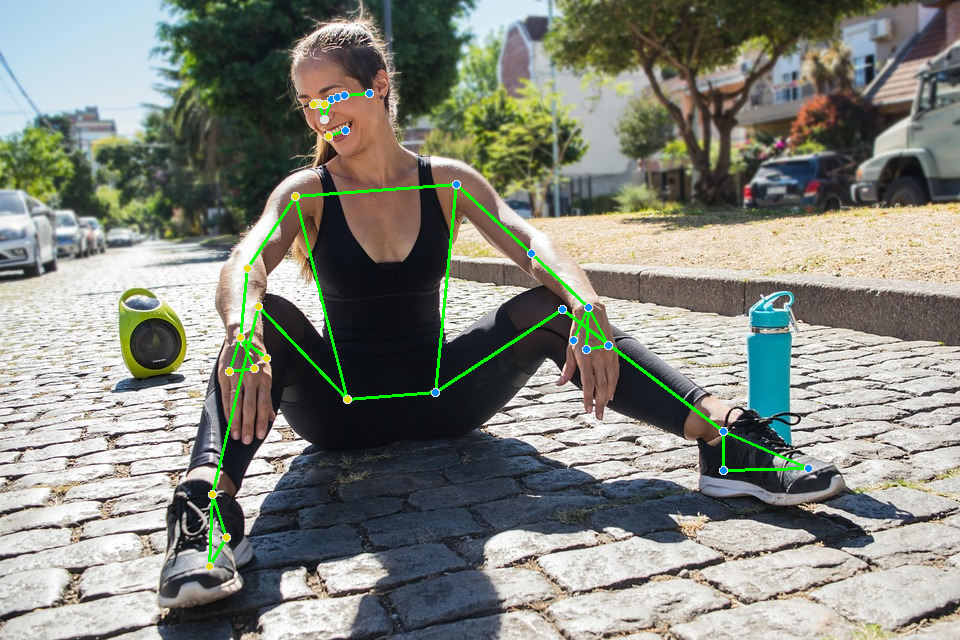

In [7]:
# STEP 1: Import the necessary modules.
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# STEP 2: Create an PoseLandmarker object.
base_options = python.BaseOptions(model_asset_path=model_path)
options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    output_segmentation_masks=True)
detector = vision.PoseLandmarker.create_from_options(options)

# STEP 3: Load the input image.
image = mp.Image.create_from_file("image.jpg")

# STEP 4: Detect pose landmarks from the input image.
detection_result = detector.detect(image)

# STEP 5: Process the detection result. In this case, visualize it.
annotated_image = draw_landmarks_on_image(image.numpy_view(), detection_result)
cv2_imshow(cv2.cvtColor(annotated_image, cv2.COLOR_RGB2BGR))

Visualize the pose segmentation mask.

In [8]:
segmentation_mask = detection_result.segmentation_masks[0].numpy_view()
segmentation_mask = np.squeeze(segmentation_mask)

# Convert to 3‑channel uint8 image for visualization.
visualized_mask = (segmentation_mask * 255).astype(np.uint8)
visualized_mask = np.stack([visualized_mask]*3, axis=-1)

Model: /root/.cache/huggingface/hub/models--litert-community--MediaPipe-PoseLandmarker-Heavy/snapshots/8a9deee6a176119dbaf22006b4a1db71fd889d82/pose_landmarker_heavy.task
Upload your fencing video:


Saving 54a8969e53064942176789511350eab8.mp4 to 54a8969e53064942176789511350eab8.mp4
Video: 54a8969e53064942176789511350eab8.mp4
FPS: 26.0022462034279
Resolution: 720 x 1280
Total frames: 142
Processing video...
Processed 100/142 frames

Processing complete!
Video: /content/fencing_output/fencing_skeleton.mp4
NumPy: /content/fencing_output/fencing_skeleton.npz
CSV: /content/fencing_output/fencing_skeleton.csv
2D shape: (142, 33, 3)
3D shape: (142, 33, 3)
Timestamps: (142,)
Detected frames: 142 / 142


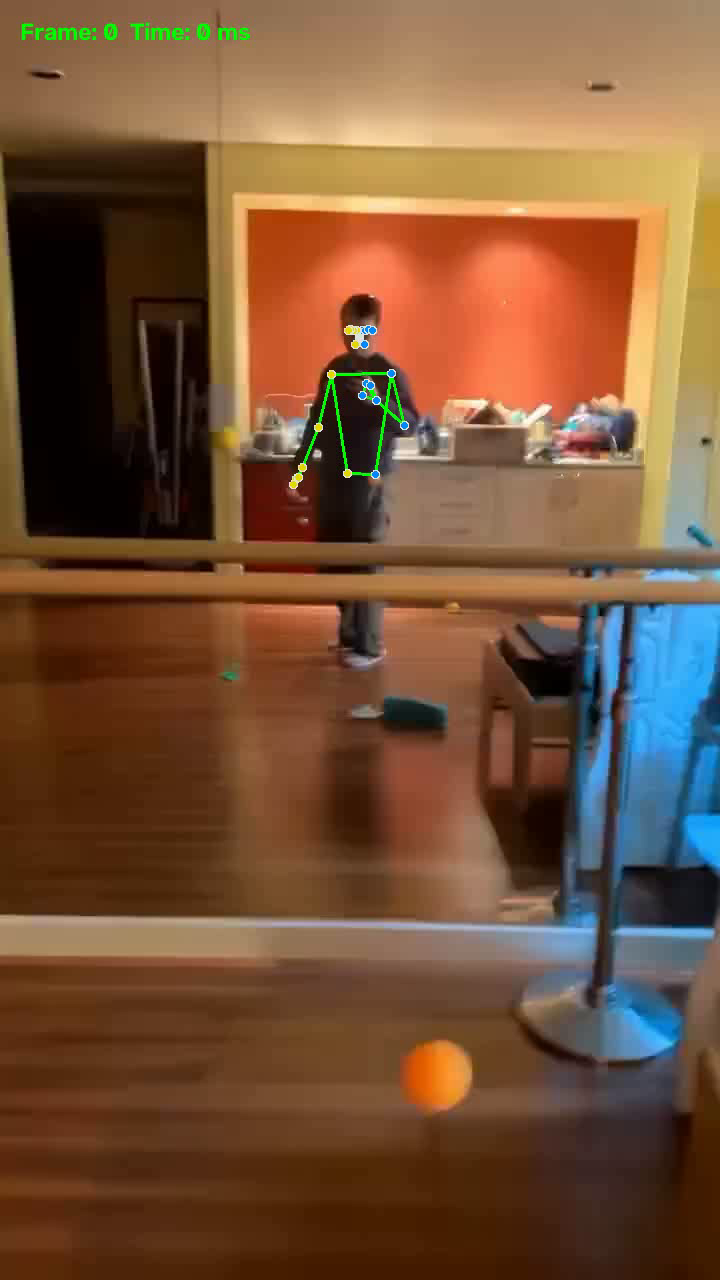

In [9]:

import os
import cv2
import numpy as np
import pandas as pd
import mediapipe as mp

from huggingface_hub import hf_hub_download
from google.colab import files
from google.colab.patches import cv2_imshow
from IPython.display import Video, display

from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from mediapipe.tasks.python.vision import drawing_utils
from mediapipe.tasks.python.vision import drawing_styles


# =====================================================
# 1. Configuration
# =====================================================

OUTPUT_DIR = "/content/fencing_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

OUTPUT_VIDEO = f"{OUTPUT_DIR}/fencing_skeleton.mp4"
OUTPUT_NPZ = f"{OUTPUT_DIR}/fencing_skeleton.npz"
OUTPUT_CSV = f"{OUTPUT_DIR}/fencing_skeleton.csv"

NUM_POSES = 1

print("Downloading MediaPipe Pose Landmarker Heavy...")

model_path = hf_hub_download(
    repo_id="litert-community/MediaPipe-PoseLandmarker-Heavy",
    filename="pose_landmarker_heavy.task"
)

print("Model:", model_path)


# =====================================================
# 2. Upload video
# =====================================================

print("Upload your fencing video:")

uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No video uploaded.")

VIDEO_PATH = next(iter(uploaded.keys()))

cap = cv2.VideoCapture(VIDEO_PATH)

if not cap.isOpened():
    raise RuntimeError(f"Cannot open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)

if not np.isfinite(fps) or fps <= 0:
    raise RuntimeError("Invalid video FPS.")

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("Video:", VIDEO_PATH)
print("FPS:", fps)
print("Resolution:", width, "x", height)
print("Total frames:", total_frames)


# =====================================================
# 3. Skeleton visualization
# =====================================================

def draw_landmarks_on_image(rgb_image, detection_result):

    annotated_image = np.copy(rgb_image[:, :, :3])

    pose_landmark_style = (
        drawing_styles.get_default_pose_landmarks_style()
    )

    pose_connection_style = drawing_utils.DrawingSpec(
        color=(0, 255, 0),
        thickness=2
    )

    for pose_landmarks in detection_result.pose_landmarks:

        drawing_utils.draw_landmarks(
            image=annotated_image,
            landmark_list=pose_landmarks,
            connections=vision.PoseLandmarksConnections.POSE_LANDMARKS,
            landmark_drawing_spec=pose_landmark_style,
            connection_drawing_spec=pose_connection_style
        )

    return annotated_image


# =====================================================
# 4. Initialize Pose Landmarker
# =====================================================

base_options = python.BaseOptions(
    model_asset_path=model_path
)

options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_poses=NUM_POSES,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5,
    output_segmentation_masks=False
)


# =====================================================
# 5. Video writer
# =====================================================

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    OUTPUT_VIDEO,
    fourcc,
    fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Cannot create output video.")


# =====================================================
# 6. Storage
# =====================================================

all_skeleton_2d = []
all_skeleton_3d = []
all_timestamps = []
all_detected = []

csv_rows = []

frame_id = 0
last_timestamp = -1

print("Processing video...")


# =====================================================
# 7. Main processing loop
# =====================================================

try:
    with vision.PoseLandmarker.create_from_options(options) as detector:

        while cap.isOpened():

            success, frame = cap.read()

            if not success:
                break

            # BGR -> RGB
            rgb = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            # Frame-based timestamps for constant-FPS video.
            timestamp_ms = int(round(
                frame_id * 1000.0 / fps
            ))

            # MediaPipe requires strictly increasing timestamps.
            timestamp_ms = max(
                timestamp_ms,
                last_timestamp + 1
            )
            last_timestamp = timestamp_ms

            # Pose detection
            result = detector.detect_for_video(
                mp_image,
                timestamp_ms
            )

            # Default missing skeleton: NaN
            skeleton_2d = np.full(
                (33, 3),
                np.nan,
                dtype=np.float32
            )

            skeleton_3d = np.full(
                (33, 3),
                np.nan,
                dtype=np.float32
            )

            detected = bool(
                result.pose_landmarks and
                result.pose_world_landmarks
            )

            if result.pose_landmarks:

                landmarks_2d = result.pose_landmarks[0]

                skeleton_2d = np.array([
                    [p.x, p.y, p.z]
                    for p in landmarks_2d
                ], dtype=np.float32)

            if result.pose_world_landmarks:

                landmarks_3d = result.pose_world_landmarks[0]

                skeleton_3d = np.array([
                    [p.x, p.y, p.z]
                    for p in landmarks_3d
                ], dtype=np.float32)

            # Save skeleton arrays
            all_skeleton_2d.append(skeleton_2d)
            all_skeleton_3d.append(skeleton_3d)
            all_timestamps.append(timestamp_ms)
            all_detected.append(detected)

            # Save long-format CSV rows
            for joint_id in range(33):

                csv_rows.append({
                    "frame": frame_id,
                    "timestamp_ms": timestamp_ms,
                    "detected": detected,
                    "joint_id": joint_id,
                    "x2d": skeleton_2d[joint_id, 0],
                    "y2d": skeleton_2d[joint_id, 1],
                    "z2d": skeleton_2d[joint_id, 2],
                    "x3d": skeleton_3d[joint_id, 0],
                    "y3d": skeleton_3d[joint_id, 1],
                    "z3d": skeleton_3d[joint_id, 2]
                })

            # Draw skeleton
            annotated_rgb = draw_landmarks_on_image(
                rgb,
                result
            )

            annotated_bgr = cv2.cvtColor(
                annotated_rgb,
                cv2.COLOR_RGB2BGR
            )

            # Add frame information
            cv2.putText(
                annotated_bgr,
                f"Frame: {frame_id}  Time: {timestamp_ms} ms",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 0),
                2
            )

            writer.write(annotated_bgr)

            frame_id += 1

            if frame_id % 100 == 0:
                print(
                    f"Processed {frame_id}/{total_frames} frames"
                )

finally:
    cap.release()
    writer.release()


# =====================================================
# 8. Export NumPy data
# =====================================================

skeleton_2d_array = np.asarray(
    all_skeleton_2d,
    dtype=np.float32
)

skeleton_3d_array = np.asarray(
    all_skeleton_3d,
    dtype=np.float32
)

timestamps_array = np.asarray(
    all_timestamps,
    dtype=np.int64
)

detected_array = np.asarray(
    all_detected,
    dtype=bool
)

np.savez_compressed(
    OUTPUT_NPZ,
    skeleton_2d=skeleton_2d_array,
    skeleton_3d=skeleton_3d_array,
    timestamps_ms=timestamps_array,
    detected=detected_array,
    fps=fps
)


# =====================================================
# 9. Export CSV
# =====================================================

df = pd.DataFrame(csv_rows)
df.to_csv(OUTPUT_CSV, index=False)


# =====================================================
# 10. Results
# =====================================================

print("\nProcessing complete!")

print("Video:", OUTPUT_VIDEO)
print("NumPy:", OUTPUT_NPZ)
print("CSV:", OUTPUT_CSV)

print("2D shape:", skeleton_2d_array.shape)
print("3D shape:", skeleton_3d_array.shape)
print("Timestamps:", timestamps_array.shape)

print(
    "Detected frames:",
    np.sum(detected_array),
    "/",
    len(detected_array)
)

# Display first annotated frame
preview_cap = cv2.VideoCapture(OUTPUT_VIDEO)
ok, preview = preview_cap.read()
preview_cap.release()

if ok:
    cv2_imshow(preview)


In [10]:
# Convert to browser-compatible H.264
!ffmpeg -y -loglevel error \
  -i /content/fencing_output/fencing_skeleton.mp4 \
  -c:v libx264 -pix_fmt yuv420p \
  /content/fencing_output/fencing_preview.mp4

display(Video(
    "/content/fencing_output/fencing_preview.mp4",
    embed=True
))

In [11]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/fencing_results",
    "zip",
    "/content/fencing_output"
)

files.download("/content/fencing_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>